In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve

RANDOM_STATE = 42

## 1. Get & understand the data

In [4]:
df = sns.load_dataset("titanic")  # load the titanic data from seaborn
df.head() 

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [46]:
df.shape  # size of data (rows, columns)

(891, 11)

In [6]:
df.info()  # column types and missing values

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [7]:
df.describe()  # summary of the number columns

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
df["survived"].value_counts()  # how many died (0) and survived (1)

survived
0    549
1    342
Name: count, dtype: int64

In [48]:
df["survived"].value_counts(normalize=True)  # same counts as percentages

survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

In [49]:
df["survived"].value_counts(normalize=True)  # same counts as percentages

survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

## 2. Explore & clean the data

In [11]:
df.isnull().sum()  # missing values per column

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [12]:
df.duplicated().sum()  # number of duplicate rows

np.int64(107)

In [50]:
df[df["fare"] == 0].shape[0]  # passengers with a fare of 0 (unusual value)

15

In [52]:
df[["sex", "embarked", "pclass"]].nunique()  # how many categories in each categorical column

sex         2
embarked    3
pclass      3
dtype: int64

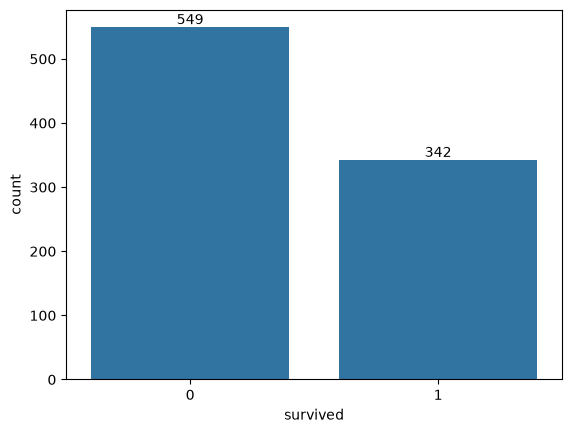

In [17]:
ax = sns.countplot(x="survived", data=df)  # class balance: died vs survived
ax.bar_label(ax.containers[0])  # write the count on top of each bar
plt.show()

In [19]:
df = df.drop(columns=["deck", "alive", "embark_town", "class"])  # deck has too many gaps, the other 3 repeat other columns

In [20]:
df["age"] = df["age"].fillna(df["age"].median())  # fill gaps with the median age

In [22]:
df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])  # fillgaps with the most common port

In [24]:
df.isnull().sum()  # final checks

survived      0
pclass        0
sex           0
age           0
sibsp         0
parch         0
fare          0
embarked      0
who           0
adult_male    0
alone         0
dtype: int64

## 3. Choose X and y variables

In [25]:
y = df["survived"]  # what we want to predict

In [26]:
X = df[["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]]  # inputs the model learns from

## 4. Check initial logistic regression assumptions

In [32]:
y.unique()  # checking binary target

array([0, 1])

In [35]:
X.shape  # sample size

(891, 8)

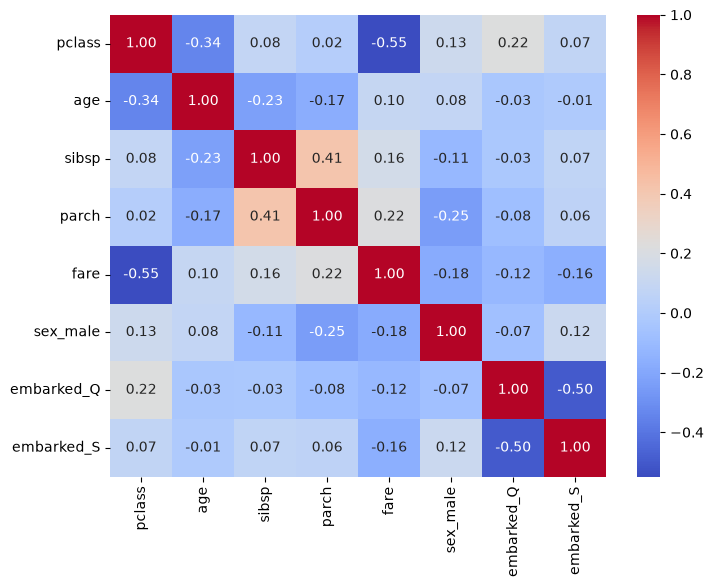

In [36]:
plt.figure(figsize=(8, 6))  # make the chart bigger
sns.heatmap(X.corr(), annot=True, cmap="coolwarm", fmt=".2f")  # correlation between inputs, look for values near 1 or -1
plt.show()

## 5. Split into training & test data

In [39]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)  # 80% train, 20% test, stratify keeps the died/survived ratio the same in both

In [40]:
print(X_train.shape, X_test.shape)  # rows and columns in train and test

(712, 8) (179, 8)


In [41]:
print(y_train.value_counts(normalize=True))  # died/survived % in train
print(y_test.value_counts(normalize=True))  # died/survived % in test

survived
0    0.616573
1    0.383427
Name: proportion, dtype: float64
survived
0    0.614525
1    0.385475
Name: proportion, dtype: float64


For sabs info The data was split 80/20 (712 train, 179 test) with stratify, so both sets keep the same 62% died / 38% survived balance.

## 6. Create & train the model